In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation_metadata.csv
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/train_metadata.csv
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test_metadata.csv
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation/Tampered_Forged/signature_forged_forgeries_22_17.png
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation/Tampered_Forged/signature_forged_forgeries_52_20.png
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation/Tampered_Forged/signature_forged_forgeries_4_6.png
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation/Tampered_Forged/signature_forged_forgeries_53_14.png
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/valid

In [3]:
import os

print("===== DATASET STRUCTURE =====")

base_path = "/kaggle/input/financial_tamper_dataset"

print("Base path exists:", os.path.exists(base_path))

if os.path.exists(base_path):
    for root, dirs, files in os.walk(base_path):
        level = root.replace(base_path, "").count(os.sep)
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        if level >= 3:
            continue

        for file in files[:10]:
            print(f"{indent}    {file}")
else:
    print("Dataset path not found.")
    print("\nAvailable /kaggle/input items:")

    for item in os.listdir("/kaggle/input"):
        print(" -", item)

===== DATASET STRUCTURE =====
Base path exists: False
Dataset path not found.

Available /kaggle/input items:
 - datasets


In [4]:
import os

base = "/kaggle/input/datasets"

print("===== DATASETS UNDER /kaggle/input/datasets =====\n")

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    # Show directories up to a reasonable depth
    if level <= 4:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")

===== DATASETS UNDER /kaggle/input/datasets =====

datasets/
    pmaheswarraju/
        financial-tamper-dataset/
            FinGuard_Final_Dataset/
                validation_metadata.csv
                train_metadata.csv
                test_metadata.csv
                validation/
                test/
                train/


In [5]:
import os

BASE_PATH = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset"

for split in ["train", "validation", "test"]:
    split_path = os.path.join(BASE_PATH, split)

    print(f"\n===== {split.upper()} =====")

    if not os.path.exists(split_path):
        print("Split not found!")
        continue

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            files = [
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
            ]

            print(f"{class_name}: {len(files)} images")


===== TRAIN =====
Authentic: 1501 images
Tampered_Forged: 1038 images

===== VALIDATION =====
Authentic: 322 images
Tampered_Forged: 222 images

===== TEST =====
Authentic: 322 images
Tampered_Forged: 223 images


In [6]:
import pandas as pd
import os

for split in ["train", "validation", "test"]:
    csv_path = os.path.join(BASE_PATH, f"{split}_metadata.csv")

    print(f"\n===== {split.upper()} METADATA =====")

    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)

        print("Shape:", df.shape)
        print("Columns:")
        print(df.columns.tolist())

        print("\nFirst 5 rows:")
        display(df.head())
    else:
        print("Metadata file not found.")


===== TRAIN METADATA =====
Shape: (2539, 7)
Columns:
['filename', 'document_type', 'class', 'source_dataset', 'original_split', 'original_filename', 'stratify_group']

First 5 rows:


,filename,document_type,class,source_dataset,original_split,original_filename,stratify_group
0,receipt_auth_train_X51006387971.png,Receipt,Authentic,Find it again!,train,X51006387971.png,Receipt_Authentic
1,signature_forged_forgeries_55_11.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_55_11.png,Signature_Tampered_Forged
2,signature_forged_forgeries_48_8.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_48_8.png,Signature_Tampered_Forged
3,signature_forged_forgeries_54_2.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_54_2.png,Signature_Tampered_Forged
4,signature_auth_original_33_1.png,Signature,Authentic,CEDAR,Not Applicable,original_33_1.png,Signature_Authentic



===== VALIDATION METADATA =====
Shape: (544, 7)
Columns:
['filename', 'document_type', 'class', 'source_dataset', 'original_split', 'original_filename', 'stratify_group']

First 5 rows:


,filename,document_type,class,source_dataset,original_split,original_filename,stratify_group
0,receipt_auth_train_X51005301661.png,Receipt,Authentic,Find it again!,train,X51005301661.png,Receipt_Authentic
1,signature_forged_forgeries_27_19.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_27_19.png,Signature_Tampered_Forged
2,signature_forged_forgeries_4_18.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_4_18.png,Signature_Tampered_Forged
3,signature_auth_original_53_22.png,Signature,Authentic,CEDAR,Not Applicable,original_53_22.png,Signature_Authentic
4,signature_forged_forgeries_32_9.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_32_9.png,Signature_Tampered_Forged



===== TEST METADATA =====
Shape: (545, 7)
Columns:
['filename', 'document_type', 'class', 'source_dataset', 'original_split', 'original_filename', 'stratify_group']

First 5 rows:


,filename,document_type,class,source_dataset,original_split,original_filename,stratify_group
0,signature_auth_original_43_6.png,Signature,Authentic,CEDAR,Not Applicable,original_43_6.png,Signature_Authentic
1,signature_forged_forgeries_34_23.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_34_23.png,Signature_Tampered_Forged
2,signature_forged_forgeries_42_18.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_42_18.png,Signature_Tampered_Forged
3,signature_auth_original_35_8.png,Signature,Authentic,CEDAR,Not Applicable,original_35_8.png,Signature_Authentic
4,signature_forged_forgeries_51_24.png,Signature,Tampered_Forged,CEDAR,Not Applicable,forgeries_51_24.png,Signature_Tampered_Forged


In [7]:
import pandas as pd
import os

BASE_PATH = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset"

train_meta = pd.read_csv(os.path.join(BASE_PATH, "train_metadata.csv"))
val_meta = pd.read_csv(os.path.join(BASE_PATH, "validation_metadata.csv"))
test_meta = pd.read_csv(os.path.join(BASE_PATH, "test_metadata.csv"))

# Check exact filename overlap
train_files = set(train_meta["filename"])
val_files = set(val_meta["filename"])
test_files = set(test_meta["filename"])

print("===== FILENAME OVERLAP =====")
print("Train ∩ Validation:", len(train_files & val_files))
print("Train ∩ Test:", len(train_files & test_files))
print("Validation ∩ Test:", len(val_files & test_files))

# Check original filename + source dataset overlap
def make_key(df):
    return set(
        zip(
            df["source_dataset"].astype(str),
            df["original_filename"].astype(str)
        )
    )

train_keys = make_key(train_meta)
val_keys = make_key(val_meta)
test_keys = make_key(test_meta)

print("\n===== SOURCE + ORIGINAL FILENAME OVERLAP =====")
print("Train ∩ Validation:", len(train_keys & val_keys))
print("Train ∩ Test:", len(train_keys & test_keys))
print("Validation ∩ Test:", len(val_keys & test_keys))

===== FILENAME OVERLAP =====
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

===== SOURCE + ORIGINAL FILENAME OVERLAP =====
Train ∩ Validation: 1
Train ∩ Test: 0
Validation ∩ Test: 0


In [8]:
overlap = train_keys & val_keys

print("===== TRAIN / VALIDATION OVERLAP =====")

for source, original in overlap:
    print("Source dataset :", source)
    print("Original file  :", original)

    print("\nTrain record:")
    print(
        train_meta[
            (train_meta["source_dataset"].astype(str) == source) &
            (train_meta["original_filename"].astype(str) == original)
        ].to_string(index=False)
    )

    print("\nValidation record:")
    print(
        val_meta[
            (val_meta["source_dataset"].astype(str) == source) &
            (val_meta["original_filename"].astype(str) == original)
        ].to_string(index=False)
    )

===== TRAIN / VALIDATION OVERLAP =====
Source dataset : Find it again!
Original file  : X51006619709.png

Train record:
                           filename document_type     class source_dataset original_split original_filename    stratify_group
receipt_auth_train_X51006619709.png       Receipt Authentic Find it again!          train  X51006619709.png Receipt_Authentic

Validation record:
                             filename document_type           class source_dataset original_split original_filename          stratify_group
receipt_forged_train_X51006619709.png       Receipt Tampered_Forged Find it again!          train  X51006619709.png Receipt_Tampered_Forged


In [9]:
import os

train_file = os.path.join(
    BASE_PATH,
    "train",
    "Authentic",
    "receipt_auth_train_X51006619709.png"
)

val_file = os.path.join(
    BASE_PATH,
    "validation",
    "Tampered_Forged",
    "receipt_forged_train_X51006619709.png"
)

print("Train file exists:", os.path.exists(train_file))
print("Validation file exists:", os.path.exists(val_file))

print("\nTrain path:")
print(train_file)

print("\nValidation path:")
print(val_file)

Train file exists: True
Validation file exists: True

Train path:
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/train/Authentic/receipt_auth_train_X51006619709.png

Validation path:
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation/Tampered_Forged/receipt_forged_train_X51006619709.png


Train image size: (884, 2822)
Validation image size: (884, 2822)


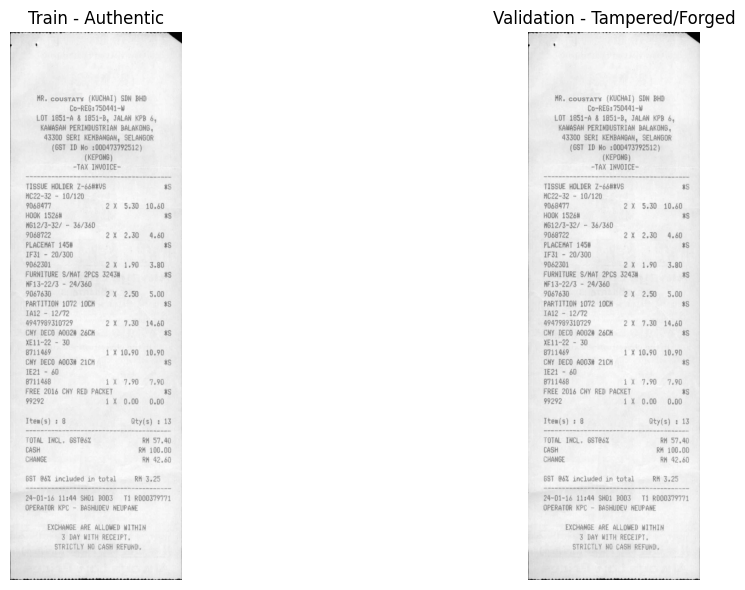

In [10]:
from PIL import Image
import matplotlib.pyplot as plt

# Load the two potentially related images
train_img = Image.open(train_file).convert("RGB")
val_img = Image.open(val_file).convert("RGB")

print("Train image size:", train_img.size)
print("Validation image size:", val_img.size)

# Display side by side
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(train_img)
plt.title("Train - Authentic")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(val_img)
plt.title("Validation - Tampered/Forged")
plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import os
import pandas as pd

BASE_PATH = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset"

train_meta = pd.read_csv(os.path.join(BASE_PATH, "train_metadata.csv"))
val_meta = pd.read_csv(os.path.join(BASE_PATH, "validation_metadata.csv"))
test_meta = pd.read_csv(os.path.join(BASE_PATH, "test_metadata.csv"))

# Exclude the one potentially related forged image from validation
LEAK_FILE = "receipt_forged_train_X51006619709.png"

val_meta_clean = val_meta[
    val_meta["filename"] != LEAK_FILE
].copy()

print("Original validation samples:", len(val_meta))
print("Clean validation samples:", len(val_meta_clean))
print("Removed:", len(val_meta) - len(val_meta_clean))

print("\nClean validation distribution:")
print(val_meta_clean["class"].value_counts())

Original validation samples: 544
Clean validation samples: 543
Removed: 1

Clean validation distribution:
class
Authentic          322
Tampered_Forged    221
Name: count, dtype: int64


In [12]:
import os
from PIL import Image

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def check_images(metadata, split_name):
    valid = 0
    corrupted = []

    for filename in metadata["filename"]:
        class_name = metadata.loc[
            metadata["filename"] == filename, "class"
        ].iloc[0]

        image_path = os.path.join(
            BASE_PATH,
            split_name,
            class_name,
            filename
        )

        try:
            with Image.open(image_path) as img:
                img.verify()
            valid += 1
        except Exception as e:
            corrupted.append((filename, str(e)))

    print(f"{split_name}:")
    print("  Valid images:", valid)
    print("  Corrupted images:", len(corrupted))

    if corrupted:
        print("\nCorrupted files:")
        for item in corrupted[:20]:
            print(item)

    return corrupted

train_corrupt = check_images(train_meta, "train")
val_corrupt = check_images(val_meta_clean, "validation")
test_corrupt = check_images(test_meta, "test")

train:
  Valid images: 2539
  Corrupted images: 0
validation:
  Valid images: 543
  Corrupted images: 0
test:
  Valid images: 545
  Corrupted images: 0


In [13]:
from collections import Counter

print("===== FINAL DATASET COUNTS =====")

for name, df in [
    ("Train", train_meta),
    ("Validation", val_meta_clean),
    ("Test", test_meta)
]:
    print(f"\n{name}:")
    print("Total:", len(df))
    print(df["class"].value_counts())

===== FINAL DATASET COUNTS =====

Train:
Total: 2539
class
Authentic          1501
Tampered_Forged    1038
Name: count, dtype: int64

Validation:
Total: 543
class
Authentic          322
Tampered_Forged    221
Name: count, dtype: int64

Test:
Total: 545
class
Authentic          322
Tampered_Forged    223
Name: count, dtype: int64


In [14]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_names = ["Authentic", "Tampered_Forged"]

y_train = train_meta["class"].map({
    "Authentic": 0,
    "Tampered_Forged": 1
}).values

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weights = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("Class weights:")
print("Authentic:", class_weights[0])
print("Tampered_Forged:", class_weights[1])

Class weights:
Authentic: 0.845769487008661
Tampered_Forged: 1.2230250481695568


In [15]:
import tensorflow as tf
import numpy as np
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

label_map = {
    "Authentic": 0,
    "Tampered_Forged": 1
}

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def create_dataset(metadata, split_name, shuffle=False):
    paths = []
    labels = []

    for _, row in metadata.iterrows():
        path = os.path.join(
            BASE_PATH,
            split_name,
            row["class"],
            row["filename"]
        )

        paths.append(path)
        labels.append(label_map[row["class"]])

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = create_dataset(
    train_meta,
    "train",
    shuffle=True
)

val_ds = create_dataset(
    val_meta_clean,
    "validation",
    shuffle=False
)

test_ds = create_dataset(
    test_meta,
    "test",
    shuffle=False
)

print("Datasets created successfully.")

I0000 00:00:1789325622.699809      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Datasets created successfully.


In [16]:
# Check one batch

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image value range:", images.numpy().min(), "to", images.numpy().max())
print("Labels:", labels.numpy()[:20])


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image value range: 0.0 to 1.0
Labels: [0 0 1 0 0 0 1 0 0 1 0 0 1 1 1 1 0 0 0 0]


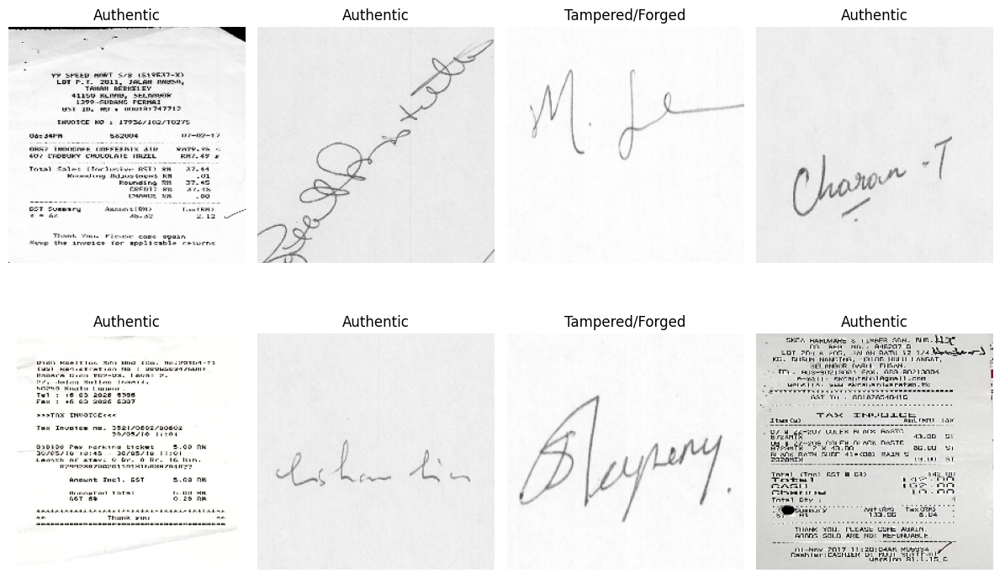

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i])
    plt.title(
        "Authentic" if labels[i].numpy() == 0 else "Tampered/Forged"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10),
], name="document_augmentation")


def build_custom_cnn(input_shape=(224, 224, 3)):

    inputs = layers.Input(shape=input_shape)

    x = data_augmentation(inputs)

    x = layers.Conv2D(
        32, (3, 3), padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(
        64, (3, 3), padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(
        128, (3, 3), padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(
        256, (3, 3), padding="same"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inputs,
        outputs,
        name="FinGuard_Document_Custom_CNN"
    )


model = build_custom_cnn()

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "FinGuard_Document_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ document_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [19]:
print("Total parameters:", model.count_params())

Total parameters: 423361


In [20]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/finguard_document_custom_cnn.keras",
    monitor="val_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_auc",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [21]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.8839 - auc: 0.9227 - loss: 0.3169 - precision: 0.8423 - recall: 0.8568
Epoch 1: val_auc improved from None to 0.31782, saving model to /kaggle/working/finguard_document_custom_cnn.keras

Epoch 1: finished saving model to /kaggle/working/finguard_document_custom_cnn.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 27s 215ms/step - accuracy: 0.9157 - auc: 0.9671 - loss: 0.2296 - precision: 0.9016 - recall: 0.8911 - val_accuracy: 0.4070 - val_auc: 0.3178 - val_loss: 3.0631 - val_precision: 0.4070 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/20
79/80 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9332 - auc: 0.9781 - loss: 0.1754 - precision: 0.9328 - recall: 0.8994
Epoch 2: val_auc improved from 0.31782 to 0.51631, saving model to /kaggle/working/finguard_document_custom_cnn.keras

Epoch 2: finished saving model to /kaggle/working/finguard_document_custom_cnn.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 17s 210ms/step - accuracy: 0.9390 - au

In [22]:
# Load the best saved model
best_model = tf.keras.models.load_model(
    "/kaggle/working/finguard_document_custom_cnn.keras"
)

print("Best model loaded successfully.")
print("Total parameters:", best_model.count_params())

Best model loaded successfully.
Total parameters: 423361


In [23]:
# Evaluate on untouched test set
test_results = best_model.evaluate(
    test_ds,
    return_dict=True,
    verbose=1
)

print("\nTest Results:")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 175ms/step - accuracy: 0.9523 - auc: 0.9762 - loss: 0.1473 - precision: 0.9950 - recall: 0.8879

Test Results:
accuracy: 0.9523
auc: 0.9762
loss: 0.1473
precision: 0.9950
recall: 0.8879


In [24]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# True labels
y_true = np.concatenate([
    y.numpy() for _, y in test_ds
])

# Predictions
y_prob = best_model.predict(test_ds, verbose=1).ravel()

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Authentic", "Tampered_Forged"],
        digits=4
    )
)

# ROC-AUC
auc = roc_auc_score(y_true, y_prob)
print(f"ROC-AUC: {auc:.4f}")

18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 168ms/step
Confusion Matrix:
[[321   1]
 [ 25 198]]

Classification Report:
                 precision    recall  f1-score   support

      Authentic     0.9277    0.9969    0.9611       322
Tampered_Forged     0.9950    0.8879    0.9384       223

       accuracy                         0.9523       545
      macro avg     0.9614    0.9424    0.9497       545
   weighted avg     0.9553    0.9523    0.9518       545

ROC-AUC: 0.9762


In [25]:
import time
import numpy as np

# Get one batch to warm up the model
images, labels = next(iter(test_ds))
_ = best_model.predict(images, verbose=0)

# Measure inference time over the complete test set
total_images = 0
total_time = 0.0

for images, labels in test_ds:
    start = time.perf_counter()
    _ = best_model.predict(images, verbose=0)
    end = time.perf_counter()

    total_time += (end - start)
    total_images += images.shape[0]

avg_time_ms = (total_time / total_images) * 1000

print(f"Total images: {total_images}")
print(f"Total inference time: {total_time:.4f} seconds")
print(f"Average inference time: {avg_time_ms:.4f} ms/image")

Total images: 545
Total inference time: 2.3590 seconds
Average inference time: 4.3285 ms/image


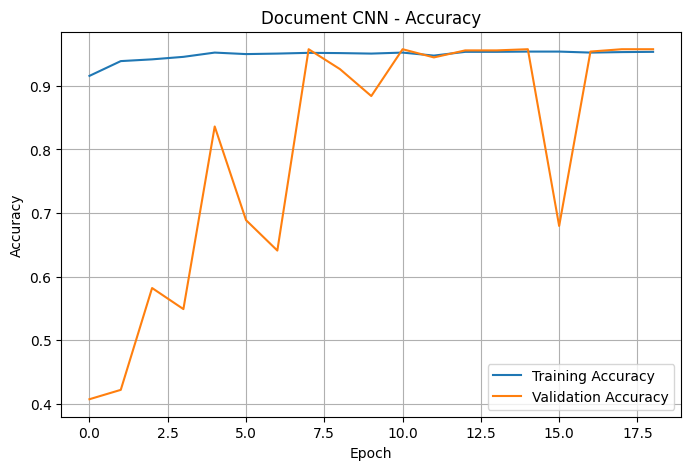

In [26]:
import matplotlib.pyplot as plt

history_dict = history.history

plt.figure(figsize=(8,5))
plt.plot(history_dict["accuracy"], label="Training Accuracy")
plt.plot(history_dict["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Document CNN - Accuracy")
plt.legend()
plt.grid(True)
plt.show()

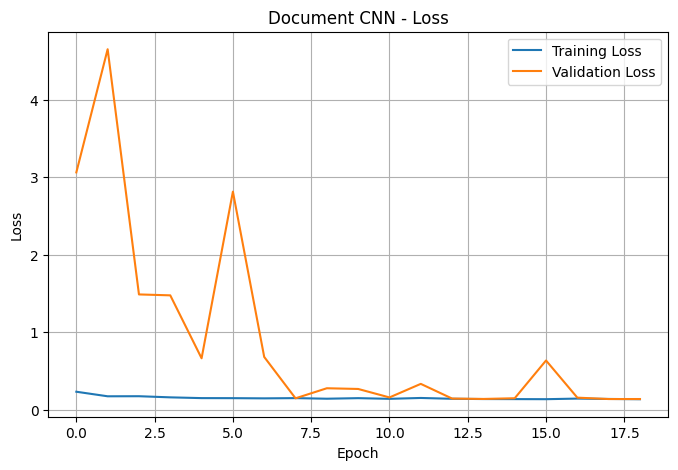

In [27]:
plt.figure(figsize=(8,5))
plt.plot(history_dict["loss"], label="Training Loss")
plt.plot(history_dict["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Document CNN - Loss")
plt.legend()
plt.grid(True)
plt.show()

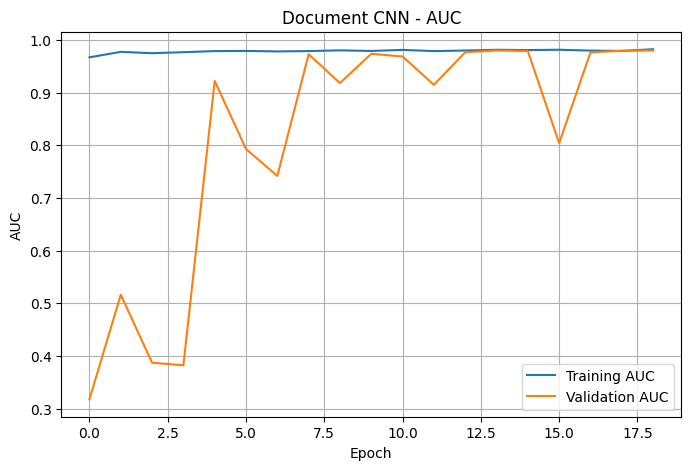

In [28]:
plt.figure(figsize=(8,5))
plt.plot(history_dict["auc"], label="Training AUC")
plt.plot(history_dict["val_auc"], label="Validation AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Document CNN - AUC")
plt.legend()
plt.grid(True)
plt.show()

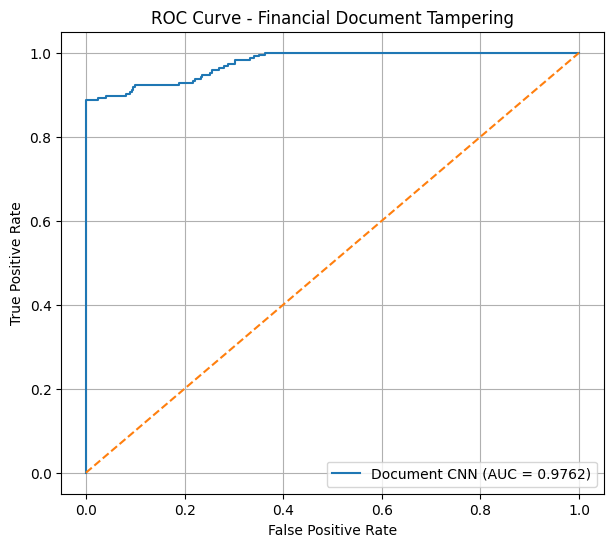

In [29]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"Document CNN (AUC = {roc_auc_value:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Financial Document Tampering")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
import os

model_path = "/kaggle/working/finguard_document_custom_cnn.keras"

size_mb = os.path.getsize(model_path) / (1024 * 1024)

print(f"Model size: {size_mb:.2f} MB")
print(f"Parameters: {best_model.count_params():,}")

Model size: 4.94 MB
Parameters: 423,361


In [31]:
from IPython.display import FileLink

FileLink("/kaggle/working/finguard_document_custom_cnn.keras")

/kaggle/working/finguard_document_custom_cnn.keras

In [32]:
import shutil

src = "/kaggle/working/finguard_document_custom_cnn.keras"
dst = "/kaggle/working/finguard_document_custom_cnn.zip"

shutil.make_archive(
    "/kaggle/working/finguard_document_custom_cnn",
    "zip",
    root_dir="/kaggle/working",
    base_dir="finguard_document_custom_cnn.keras"
)

print("Created:", dst)

Created: /kaggle/working/finguard_document_custom_cnn.zip


In [33]:
from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/finguard_document_custom_cnn.zip"
))

/kaggle/working/finguard_document_custom_cnn.zip

In [34]:
import os

model_path = "/kaggle/working/finguard_document_custom_cnn.keras"

print(os.path.exists(model_path))
print(os.path.getsize(model_path) / (1024 * 1024), "MB")

True
4.938103675842285 MB


In [35]:
MODEL_PATH = "/kaggle/working/finguard_document_custom_cnn.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")
print(MODEL_PATH)

Model saved successfully!
/kaggle/working/finguard_document_custom_cnn.keras


In [36]:
import os
import numpy as np
from PIL import Image

# Exact image path from your Kaggle Input panel
image_path = "/kaggle/input/datasets/pmaheswarraju/test-document/receipt_forged_val_X51005605335.png"

# Load trained document model
document_model = tf.keras.models.load_model(
    "/kaggle/working/finguard_document_custom_cnn.keras",
    compile=False
)

# Same preprocessing as your Flask application
img = Image.open(image_path).convert("RGB")

print("Original image size:", img.size)

img = img.resize((224, 224))

arr = np.array(img, dtype=np.float32) / 255.0
tensor = np.expand_dims(arr, axis=0)

print("Tensor shape:", tensor.shape)

# Prediction
p = float(document_model.predict(tensor, verbose=0).ravel()[0])

print("\nRaw probability:", p)

if p >= 0.60:
    prediction = "TAMPERED / FORGED"
elif p <= 0.40:
    prediction = "AUTHENTIC"
else:
    prediction = "UNCERTAIN"

print("Prediction:", prediction)

Original image size: (741, 1733)
Tensor shape: (1, 224, 224, 3)

Raw probability: 0.1486010104417801
Prediction: AUTHENTIC


In [37]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
import numpy as np

y_true = []
y_prob = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0).ravel()
    y_prob.extend(probs)
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)

# 0 = Authentic
# 1 = Tampered_Forged
y_pred = (y_prob >= 0.5).astype(int)

print("===== CONFUSION MATRIX =====")
print(confusion_matrix(y_true, y_pred))

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Authentic", "Tampered_Forged"],
    digits=4
))

print("\nROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

# Explicit error counts
false_positive = np.sum((y_true == 0) & (y_pred == 1))
false_negative = np.sum((y_true == 1) & (y_pred == 0))

print("\nFalse Positives (Authentic → Tampered):", false_positive)
print("False Negatives (Tampered → Authentic):", false_negative)

===== CONFUSION MATRIX =====
[[321   1]
 [ 25 198]]

===== CLASSIFICATION REPORT =====
                 precision    recall  f1-score   support

      Authentic     0.9277    0.9969    0.9611       322
Tampered_Forged     0.9950    0.8879    0.9384       223

       accuracy                         0.9523       545
      macro avg     0.9614    0.9424    0.9497       545
   weighted avg     0.9553    0.9523    0.9518       545


ROC-AUC: 0.9762

False Positives (Authentic → Tampered): 1
False Negatives (Tampered → Authentic): 25


In [38]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

print("Threshold Analysis")
print("=" * 70)

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    
    y_pred = (y_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print(
        f"Threshold={threshold:.2f} | "
        f"TN={tn:3d} FP={fp:3d} FN={fn:3d} TP={tp:3d} | "
        f"Tampered Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )

Threshold Analysis
Threshold=0.30 | TN=314 FP=  8 FN= 24 TP=199 | Tampered Precision=0.961 | Recall=0.892 | F1=0.926
Threshold=0.35 | TN=320 FP=  2 FN= 25 TP=198 | Tampered Precision=0.990 | Recall=0.888 | F1=0.936
Threshold=0.40 | TN=321 FP=  1 FN= 25 TP=198 | Tampered Precision=0.995 | Recall=0.888 | F1=0.938
Threshold=0.45 | TN=321 FP=  1 FN= 25 TP=198 | Tampered Precision=0.995 | Recall=0.888 | F1=0.938
Threshold=0.50 | TN=321 FP=  1 FN= 25 TP=198 | Tampered Precision=0.995 | Recall=0.888 | F1=0.938
Threshold=0.55 | TN=321 FP=  1 FN= 25 TP=198 | Tampered Precision=0.995 | Recall=0.888 | F1=0.938
Threshold=0.60 | TN=322 FP=  0 FN= 25 TP=198 | Tampered Precision=1.000 | Recall=0.888 | F1=0.941


In [39]:
MODEL_PATH = "/kaggle/working/finguard_document_custom_cnn.keras"

model.save(MODEL_PATH)

import os
print("Saved:", os.path.exists(MODEL_PATH))
print("Size:", round(os.path.getsize(MODEL_PATH)/(1024**2), 2), "MB")

Saved: True
Size: 4.94 MB


In [40]:
import numpy as np
from sklearn.metrics import confusion_matrix
import os

# Collect predictions again while keeping filenames
y_true_fn = []
y_prob_fn = []
file_paths_fn = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0).ravel()
    
    y_prob_fn.extend(probs)
    y_true_fn.extend(labels.numpy().ravel())

    # NOTE:
    # If your test_ds was created with image_dataset_from_directory,
    # we need the filenames separately.
    
print("Predictions collected:", len(y_prob_fn))

Predictions collected: 545


In [41]:
print(type(test_ds))
print(test_ds.class_names if hasattr(test_ds, "class_names") else "No class_names")
print(test_ds.file_paths[:3] if hasattr(test_ds, "file_paths") else "No file_paths")

<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
No class_names
No file_paths


In [42]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "Authentic" in dirs and "Tampered_Forged" in dirs:
        print("FOUND TEST/VALIDATION CANDIDATE:")
        print(root)

FOUND TEST/VALIDATION CANDIDATE:
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation
FOUND TEST/VALIDATION CANDIDATE:
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test
FOUND TEST/VALIDATION CANDIDATE:
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/train


In [43]:
import os
import numpy as np
from PIL import Image

TEST_DIR = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test"

def get_images(folder):
    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".JPG", ".JPEG", ".PNG")
    paths = []

    for root, _, files in os.walk(folder):
        for f in files:
            if f.endswith(extensions):
                paths.append(os.path.join(root, f))

    return sorted(paths)

authentic_files = get_images(os.path.join(TEST_DIR, "Authentic"))
tampered_files = get_images(os.path.join(TEST_DIR, "Tampered_Forged"))

print("Authentic images:", len(authentic_files))
print("Tampered images:", len(tampered_files))

Authentic images: 322
Tampered images: 223


In [44]:
false_negatives = []

for path in tampered_files:

    img = Image.open(path).convert("RGB")
    img = img.resize((224, 224))

    arr = np.array(img, dtype=np.float32) / 255.0
    tensor = np.expand_dims(arr, axis=0)

    p = float(model.predict(tensor, verbose=0).ravel()[0])

    # Model says Authentic at the standard 0.5 classification threshold
    if p < 0.5:
        false_negatives.append((path, p))

false_negatives.sort(key=lambda x: x[1])

print("=" * 90)
print("FALSE NEGATIVES: TAMPERED → AUTHENTIC")
print("=" * 90)

for i, (path, p) in enumerate(false_negatives, 1):
    print(f"{i:2d}. P(tampered)={p:.6f} | {os.path.basename(path)}")

print("\nTotal false negatives:", len(false_negatives))

FALSE NEGATIVES: TAMPERED → AUTHENTIC
 1. P(tampered)=0.113129 | receipt_forged_train_X51007339166.png
 2. P(tampered)=0.127729 | receipt_forged_val_X51007339133.png
 3. P(tampered)=0.132145 | receipt_forged_test_X51006556726.png
 4. P(tampered)=0.139747 | receipt_forged_test_X51006557117.png
 5. P(tampered)=0.148139 | receipt_forged_train_X51006555806.png
 6. P(tampered)=0.148601 | receipt_forged_val_X51005605335.png
 7. P(tampered)=0.151044 | receipt_forged_train_X51005230617.png
 8. P(tampered)=0.172220 | receipt_forged_train_X51005447850.png
 9. P(tampered)=0.174186 | receipt_forged_test_X51005757349.png
10. P(tampered)=0.189565 | receipt_forged_train_X51006556818.png
11. P(tampered)=0.190514 | receipt_forged_val_X51006008086.png
12. P(tampered)=0.192553 | receipt_forged_train_X51005757199.png
13. P(tampered)=0.195980 | receipt_forged_train_X51005365179.png
14. P(tampered)=0.197536 | receipt_forged_train_X51008142063.png
15. P(tampered)=0.212984 | receipt_forged_test_X51007103688.p

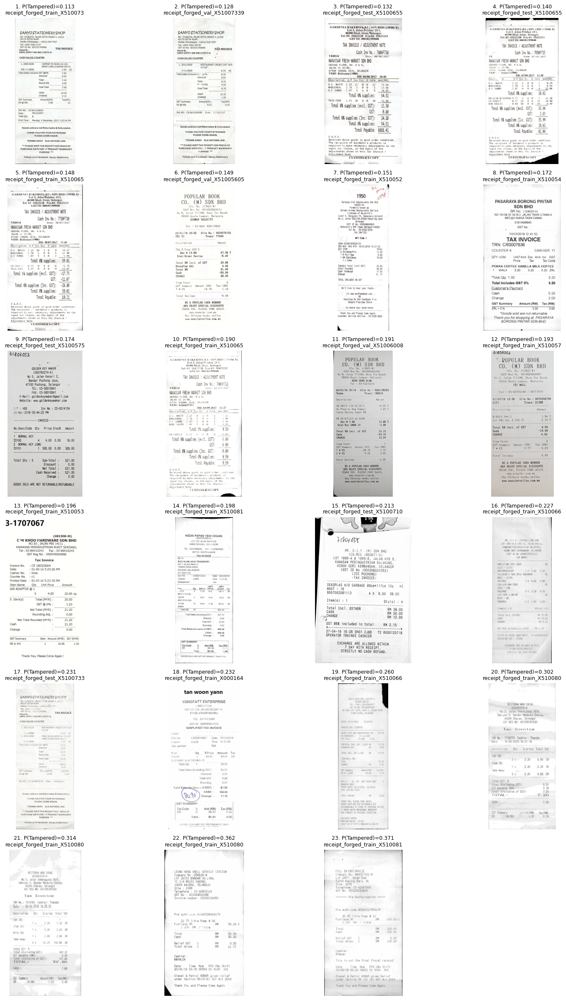

In [45]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# false_negatives should already exist from your previous code

n = len(false_negatives)

cols = 4
rows = math.ceil(n / cols)

plt.figure(figsize=(16, rows * 4))

for i, (path, p) in enumerate(false_negatives):

    img = Image.open(path).convert("RGB")

    ax = plt.subplot(rows, cols, i + 1)
    ax.imshow(img)

    ax.set_title(
        f"{i+1}. P(Tampered)={p:.3f}\n"
        f"{os.path.basename(path)[:28]}",
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
# Correctly detected tampered images
true_positives = []

for path in tampered_files:

    img = Image.open(path).convert("RGB")
    img = img.resize((224, 224))

    arr = np.array(img, dtype=np.float32) / 255.0
    tensor = np.expand_dims(arr, axis=0)

    p = float(model.predict(tensor, verbose=0).ravel()[0])

    if p >= 0.5:
        true_positives.append((path, p))

true_positives.sort(key=lambda x: x[1], reverse=True)

print("Correctly detected tampered:", len(true_positives))

Correctly detected tampered: 200


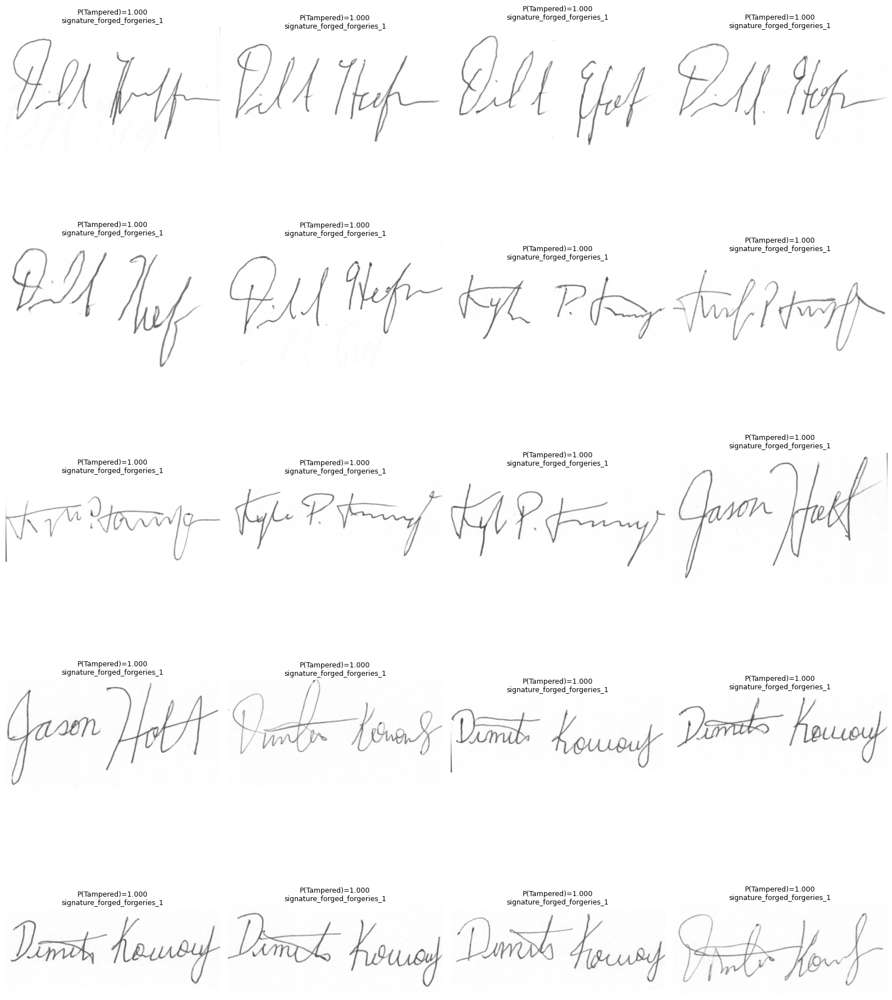

In [47]:
samples = true_positives[:20]

cols = 4
rows = math.ceil(len(samples) / cols)

plt.figure(figsize=(16, rows * 4))

for i, (path, p) in enumerate(samples):

    img = Image.open(path).convert("RGB")

    ax = plt.subplot(rows, cols, i + 1)
    ax.imshow(img)

    ax.set_title(
        f"P(Tampered)={p:.3f}\n"
        f"{os.path.basename(path)[:28]}",
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [48]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import math

TEST_DIR = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test"

tampered_dir = os.path.join(TEST_DIR, "Tampered_Forged")

tampered_test_files = []

extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp",
              ".JPG", ".JPEG", ".PNG")

for root, _, files in os.walk(tampered_dir):
    for f in files:
        if f.endswith(extensions):
            tampered_test_files.append(os.path.join(root, f))

tampered_test_files = sorted(tampered_test_files)

print("Tampered TEST images:", len(tampered_test_files))
print("Example paths:")
for p in tampered_test_files[:5]:
    print(p)

Tampered TEST images: 223
Example paths:
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test/Tampered_Forged/receipt_forged_test_X51005757349.png
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test/Tampered_Forged/receipt_forged_test_X51006556726.png
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test/Tampered_Forged/receipt_forged_test_X51006557117.png
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test/Tampered_Forged/receipt_forged_test_X51007103688.png
/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test/Tampered_Forged/receipt_forged_test_X51007339107.png


In [49]:
test_false_negatives = []
test_true_positives = []

for path in tampered_test_files:

    img = Image.open(path).convert("RGB")
    img = img.resize((224, 224))

    arr = np.array(img, dtype=np.float32) / 255.0
    tensor = np.expand_dims(arr, axis=0)

    p = float(model.predict(tensor, verbose=0).ravel()[0])

    if p < 0.5:
        test_false_negatives.append((path, p))
    else:
        test_true_positives.append((path, p))

print("False negatives:", len(test_false_negatives))
print("True positives:", len(test_true_positives))

False negatives: 23
True positives: 200


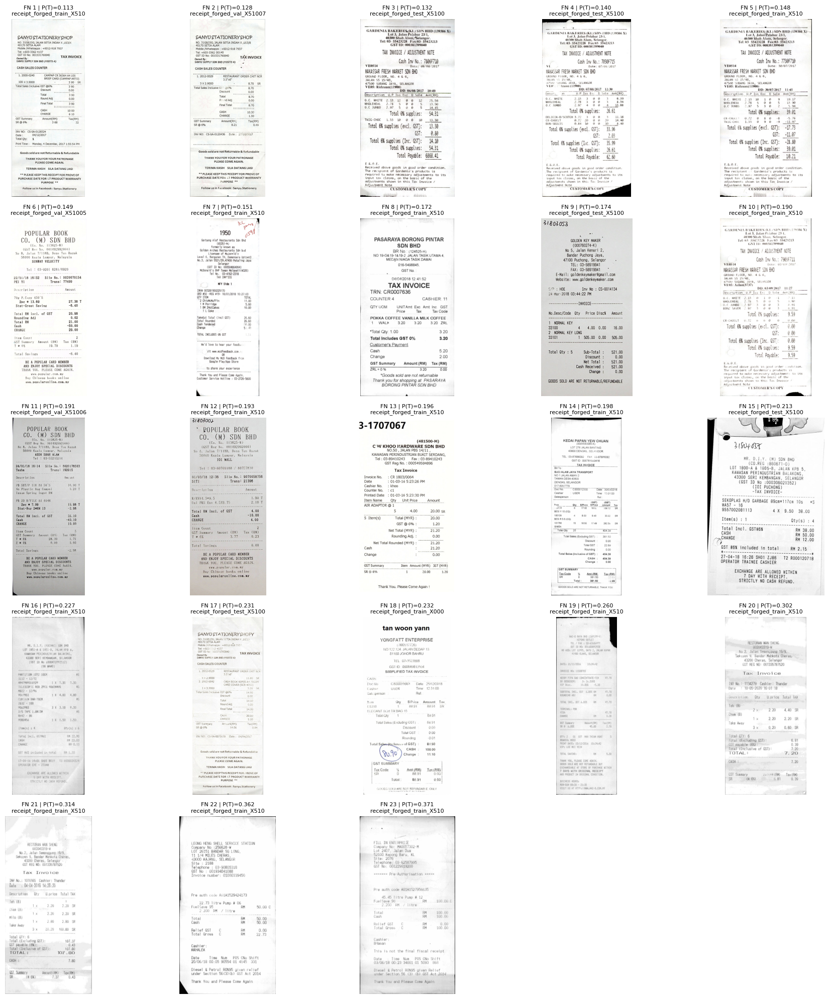

In [50]:
test_false_negatives.sort(key=lambda x: x[1])

samples = test_false_negatives

cols = 5
rows = math.ceil(len(samples) / cols)

plt.figure(figsize=(18, rows * 4))

for i, (path, p) in enumerate(samples):

    img = Image.open(path).convert("RGB")

    ax = plt.subplot(rows, cols, i + 1)
    ax.imshow(img)

    ax.set_title(
        f"FN {i+1} | P(T)={p:.3f}\n"
        f"{os.path.basename(path)[:25]}",
        fontsize=8
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

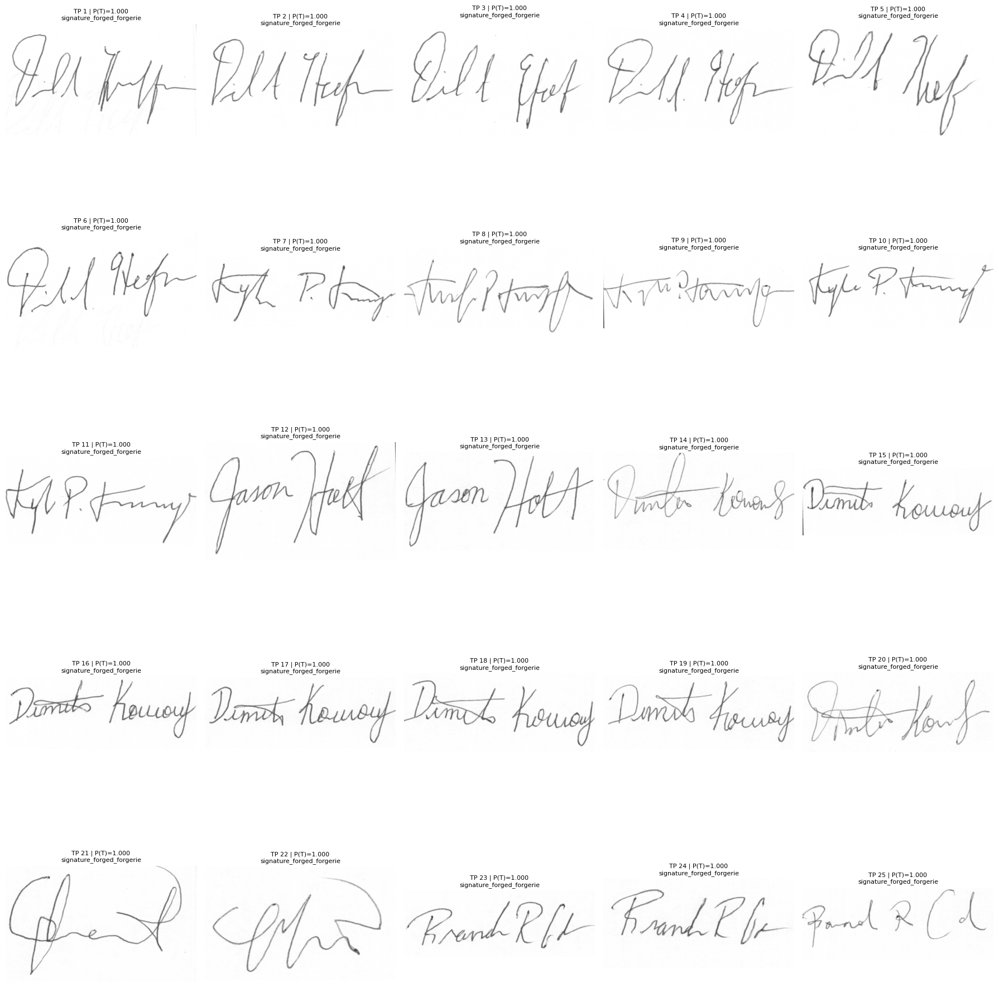

In [52]:
test_true_positives.sort(key=lambda x: x[1], reverse=True)

samples = test_true_positives[:25]

cols = 5
rows = math.ceil(len(samples) / cols)

plt.figure(figsize=(18, rows * 4))

for i, (path, p) in enumerate(samples):

    img = Image.open(path).convert("RGB")

    ax = plt.subplot(rows, cols, i + 1)
    ax.imshow(img)

    ax.set_title(
        f"TP {i+1} | P(T)={p:.3f}\n"
        f"{os.path.basename(path)[:25]}",
        fontsize=8
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [53]:
print("Model:", model.name)
print("Test images:", len(tampered_test_files))

print("\nDirect file prediction:")
print("FN:", len(test_false_negatives))
print("TP:", len(test_true_positives))

Model: FinGuard_Document_Custom_CNN
Test images: 223

Direct file prediction:
FN: 23
TP: 200


In [54]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

y_true = []
y_prob = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0).ravel()

    y_true.extend(labels.numpy())
    y_prob.extend(probs)

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = (y_prob >= 0.5).astype(int)

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Authentic", "Tampered_Forged"],
    digits=4
))

print("\nROC-AUC:", roc_auc_score(y_true, y_prob))

Confusion matrix:
[[321   1]
 [ 25 198]]

Classification report:
                 precision    recall  f1-score   support

      Authentic     0.9277    0.9969    0.9611       322
Tampered_Forged     0.9950    0.8879    0.9384       223

       accuracy                         0.9523       545
      macro avg     0.9614    0.9424    0.9497       545
   weighted avg     0.9553    0.9523    0.9518       545


ROC-AUC: 0.9761997604656993


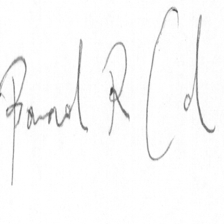

In [55]:
img.resize((224, 224))

In [56]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

DATA_DIR = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "val")
TEST_DIR  = os.path.join(DATA_DIR, "test")

IMG_SIZE = 224
BATCH_SIZE = 32

CLASS_NAMES = ["Authentic", "Tampered_Forged"]

print("TensorFlow:", tf.__version__)
print("Dataset:", DATA_DIR)

TensorFlow: 2.20.0
Dataset: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset


In [57]:
def get_image_paths(folder):
    extensions = (
        ".jpg", ".jpeg", ".png", ".bmp", ".webp",
        ".JPG", ".JPEG", ".PNG"
    )

    paths = []

    for class_idx, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(folder, class_name)

        for root, _, files in os.walk(class_dir):
            for f in files:
                if f.endswith(extensions):
                    paths.append(
                        (os.path.join(root, f), class_idx)
                    )

    return paths


train_items = get_image_paths(TRAIN_DIR)
val_items   = get_image_paths(VAL_DIR)
test_items  = get_image_paths(TEST_DIR)

print("Train:", len(train_items))
print("Validation:", len(val_items))
print("Test:", len(test_items))

Train: 2539
Validation: 0
Test: 545


In [58]:
import os

DATA_DIR = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset"

print("Contents of FinGuard_Final_Dataset:")
for item in os.listdir(DATA_DIR):
    path = os.path.join(DATA_DIR, item)
    print(
        f"{item:25s} | "
        f"{'DIR' if os.path.isdir(path) else 'FILE'}"
    )

Contents of FinGuard_Final_Dataset:
validation                | DIR
validation_metadata.csv   | FILE
test                      | DIR
train_metadata.csv        | FILE
train                     | DIR
test_metadata.csv         | FILE


In [59]:
DATA_DIR = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "validation")
TEST_DIR  = os.path.join(DATA_DIR, "test")

IMG_SIZE = 224
BATCH_SIZE = 32

CLASS_NAMES = ["Authentic", "Tampered_Forged"]

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

Train: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/train
Validation: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation
Test: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test


In [60]:
for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Test", TEST_DIR)
]:
    
    print(f"\n{split_name}")
    
    for class_name in CLASS_NAMES:
        class_dir = os.path.join(split_dir, class_name)
        
        if os.path.exists(class_dir):
            count = len([
                f for f in os.listdir(class_dir)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                )
            ])
            print(f"  {class_name}: {count}")
        else:
            print(f"  {class_name}: DIRECTORY NOT FOUND")


Train
  Authentic: 1501
  Tampered_Forged: 1038

Validation
  Authentic: 322
  Tampered_Forged: 222

Test
  Authentic: 322
  Tampered_Forged: 223


In [61]:
def get_image_paths(folder):
    
    extensions = (
        ".jpg", ".jpeg", ".png", ".bmp", ".webp",
        ".JPG", ".JPEG", ".PNG"
    )

    paths = []

    for class_idx, class_name in enumerate(CLASS_NAMES):

        class_dir = os.path.join(folder, class_name)

        for root, _, files in os.walk(class_dir):

            for f in files:

                if f.endswith(extensions):

                    paths.append(
                        (os.path.join(root, f), class_idx)
                    )

    return paths


train_items = get_image_paths(TRAIN_DIR)
val_items   = get_image_paths(VAL_DIR)
test_items  = get_image_paths(TEST_DIR)

print("Train:", len(train_items))
print("Validation:", len(val_items))
print("Test:", len(test_items))

Train: 2539
Validation: 544
Test: 545


In [63]:
def preprocess_document(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Convert to float
    image = tf.cast(image, tf.float32)

    # Preserve aspect ratio and pad to 224x224
    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE,
        method="bilinear",
        antialias=True
    )

    image = image / 255.0

    label = tf.cast(label, tf.float32)

    return image, label

In [64]:
import os

DATA_DIR = "/kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset"

folders = {
    "TRAIN": os.path.join(DATA_DIR, "train"),
    "VALIDATION": os.path.join(DATA_DIR, "validation"),
    "TEST": os.path.join(DATA_DIR, "test")
}

for split, folder in folders.items():

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    for cls in ["Authentic", "Tampered_Forged"]:

        class_folder = os.path.join(folder, cls)

        print("Path:", class_folder)

        if not os.path.exists(class_folder):
            print("❌ NOT FOUND")
            continue

        files = os.listdir(class_folder)

        image_files = [
            f for f in files
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ]

        print(cls, ":", len(image_files))


TRAIN
Path: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/train/Authentic
Authentic : 1501
Path: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/train/Tampered_Forged
Tampered_Forged : 1038

VALIDATION
Path: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation/Authentic
Authentic : 322
Path: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/validation/Tampered_Forged
Tampered_Forged : 222

TEST
Path: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test/Authentic
Authentic : 322
Path: /kaggle/input/datasets/pmaheswarraju/financial-tamper-dataset/FinGuard_Final_Dataset/test/Tampered_Forged
Tampered_Forged : 223


In [65]:
# ============================================================
# FinGuard AI - Document Tampering
# Experiment: Aspect-Ratio Preserving Preprocessing
# Same Custom CNN Architecture
# ============================================================

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

DATA_DIR = (
    "/kaggle/input/datasets/pmaheswarraju/"
    "financial-tamper-dataset/FinGuard_Final_Dataset"
)

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "validation")
TEST_DIR = os.path.join(DATA_DIR, "test")

IMG_SIZE = 224
BATCH_SIZE = 32

CLASS_NAMES = [
    "Authentic",
    "Tampered_Forged"
]

MODEL_PATH = (
    "/kaggle/working/"
    "finguard_document_custom_cnn_ar.keras"
)

print("=" * 70)
print("FinGuard AI - Document Tampering")
print("Aspect-Ratio Preserving CNN Experiment")
print("=" * 70)

print("\nTensorFlow:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Model:", MODEL_PATH)


# ------------------------------------------------------------
# 2. Collect image paths
# ------------------------------------------------------------

def get_image_paths(folder):

    extensions = (
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp",
        ".JPG",
        ".JPEG",
        ".PNG"
    )

    items = []

    for class_idx, class_name in enumerate(CLASS_NAMES):

        class_dir = os.path.join(
            folder,
            class_name
        )

        if not os.path.exists(class_dir):
            print(
                "WARNING: Missing directory:",
                class_dir
            )
            continue

        for root, _, files in os.walk(class_dir):

            for filename in files:

                if filename.endswith(extensions):

                    path = os.path.join(
                        root,
                        filename
                    )

                    items.append(
                        (path, class_idx)
                    )

    return sorted(items)


train_items = get_image_paths(TRAIN_DIR)
val_items = get_image_paths(VAL_DIR)
test_items = get_image_paths(TEST_DIR)

print("\nDataset counts:")
print("Train      :", len(train_items))
print("Validation :", len(val_items))
print("Test       :", len(test_items))


# ------------------------------------------------------------
# 3. Verify class distributions
# ------------------------------------------------------------

def print_distribution(name, items):

    counts = {
        0: 0,
        1: 0
    }

    for _, label in items:
        counts[label] += 1

    print(
        f"{name:12s}: "
        f"Authentic={counts[0]}, "
        f"Tampered={counts[1]}"
    )


print("\nClass distribution:")
print_distribution("Train", train_items)
print_distribution("Validation", val_items)
print_distribution("Test", test_items)


# ------------------------------------------------------------
# 4. Aspect-ratio preserving preprocessing
# ------------------------------------------------------------

def preprocess_document(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape(
        [None, None, 3]
    )

    image = tf.cast(
        image,
        tf.float32
    )

    # --------------------------------------------------------
    # KEY EXPERIMENT:
    #
    # Preserve original aspect ratio.
    # Resize the document so it fits inside 224x224,
    # then pad the remaining area.
    # --------------------------------------------------------

    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_SIZE,
        target_width=IMG_SIZE,
        method="bilinear",
        antialias=True
    )

    # Normalize
    image = image / 255.0

    label = tf.cast(
        label,
        tf.float32
    )

    return image, label


# ------------------------------------------------------------
# 5. Build tf.data datasets
# ------------------------------------------------------------

def make_dataset(items, shuffle=False):

    paths = [
        item[0]
        for item in items
    ]

    labels = [
        item[1]
        for item in items
    ]

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:

        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        preprocess_document,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE
    )

    ds = ds.prefetch(
        tf.data.AUTOTUNE
    )

    return ds


train_ds = make_dataset(
    train_items,
    shuffle=True
)

val_ds = make_dataset(
    val_items,
    shuffle=False
)

test_ds = make_dataset(
    test_items,
    shuffle=False
)

print("\nTensorFlow datasets created successfully.")


# ------------------------------------------------------------
# 6. Data augmentation
# ------------------------------------------------------------

data_augmentation = tf.keras.Sequential([

    layers.RandomRotation(
        0.03
    ),

    layers.RandomZoom(
        0.10
    ),

    layers.RandomTranslation(
        0.05,
        0.05
    ),

    layers.RandomContrast(
        0.10
    )

], name="document_augmentation")


# ------------------------------------------------------------
# 7. SAME Custom CNN architecture
# ------------------------------------------------------------

def build_custom_cnn(
    input_shape=(224, 224, 3)
):

    inputs = layers.Input(
        shape=input_shape
    )

    x = data_augmentation(
        inputs
    )

    # Block 1
    x = layers.Conv2D(
        32,
        (3, 3),
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # Block 2
    x = layers.Conv2D(
        64,
        (3, 3),
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # Block 3
    x = layers.Conv2D(
        128,
        (3, 3),
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # Block 4
    x = layers.Conv2D(
        256,
        (3, 3),
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)


    # Classification head
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(
        0.40
    )(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inputs,
        outputs,
        name="FinGuard_Custom_CNN_AR"
    )


model_ar = build_custom_cnn()

print("\nModel created.")

print(
    "Total parameters:",
    model_ar.count_params()
)


# ------------------------------------------------------------
# 8. Compile
# ------------------------------------------------------------

model_ar.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=3e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)


# ------------------------------------------------------------
# 9. Callbacks
# ------------------------------------------------------------

callbacks = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_auc",

        mode="max",

        patience=5,

        restore_best_weights=True,

        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_auc",

        mode="max",

        factor=0.5,

        patience=2,

        min_lr=1e-6,

        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(

        MODEL_PATH,

        monitor="val_auc",

        mode="max",

        save_best_only=True,

        verbose=1
    )
]


# ------------------------------------------------------------
# 10. Train
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STARTING TRAINING")
print("=" * 70)

history_ar = model_ar.fit(

    train_ds,

    validation_data=val_ds,

    epochs=30,

    callbacks=callbacks,

    verbose=1
)


# ------------------------------------------------------------
# 11. Load best saved model
# ------------------------------------------------------------

print("\nLoading best checkpoint...")

model_ar = tf.keras.models.load_model(
    MODEL_PATH
)

print(
    "Best model loaded:",
    MODEL_PATH
)

print(
    "Parameters:",
    model_ar.count_params()
)


# ------------------------------------------------------------
# 12. Evaluate test set
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

test_loss, test_accuracy, test_auc = model_ar.evaluate(
    test_ds,
    verbose=1
)

print("\nTest Loss     :", round(test_loss, 4))
print("Test Accuracy :", round(test_accuracy, 4))
print("Test AUC      :", round(test_auc, 4))


# ------------------------------------------------------------
# 13. Generate predictions
# ------------------------------------------------------------

y_true = []
y_prob = []

for images, labels in test_ds:

    probabilities = model_ar.predict(
        images,
        verbose=0
    ).ravel()

    y_prob.extend(
        probabilities.tolist()
    )

    y_true.extend(
        labels.numpy().tolist()
    )


y_true = np.array(
    y_true,
    dtype=int
)

y_prob = np.array(
    y_prob,
    dtype=float
)

y_pred = (
    y_prob >= 0.5
).astype(int)


# ------------------------------------------------------------
# 14. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives  :", tn)
print("False Positives :", fp)
print("False Negatives :", fn)
print("True Positives  :", tp)


# ------------------------------------------------------------
# 15. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)


# ------------------------------------------------------------
# 16. ROC-AUC
# ------------------------------------------------------------

final_auc = roc_auc_score(
    y_true,
    y_prob
)

print(
    "\nROC-AUC:",
    round(final_auc, 4)
)


# ------------------------------------------------------------
# 17. Important tampered-document metrics
# ------------------------------------------------------------

tampered_recall = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

tampered_precision = (
    tp / (tp + fp)
    if (tp + fp) > 0
    else 0
)

tampered_f1 = (
    2 * tampered_precision * tampered_recall /
    (tampered_precision + tampered_recall)
    if (tampered_precision + tampered_recall) > 0
    else 0
)

print("\n" + "=" * 70)
print("TAMPERED CLASS PERFORMANCE")
print("=" * 70)

print(
    "Tampered Precision :",
    round(tampered_precision, 4)
)

print(
    "Tampered Recall    :",
    round(tampered_recall, 4)
)

print(
    "Tampered F1        :",
    round(tampered_f1, 4)
)

print(
    "False Negatives    :",
    fn
)

print(
    "False Positives    :",
    fp
)


# ------------------------------------------------------------
# 18. Save final model
# ------------------------------------------------------------

model_ar.save(
    MODEL_PATH
)

print("\n" + "=" * 70)
print("MODEL SAVED")
print("=" * 70)

print(MODEL_PATH)
print(
    "File exists:",
    os.path.exists(MODEL_PATH)
)

FinGuard AI - Document Tampering
Aspect-Ratio Preserving CNN Experiment

TensorFlow: 2.20.0
Image size: 224
Batch size: 32
Model: /kaggle/working/finguard_document_custom_cnn_ar.keras

Dataset counts:
Train      : 2539
Validation : 544
Test       : 545

Class distribution:
Train       : Authentic=1501, Tampered=1038
Validation  : Authentic=322, Tampered=222
Test        : Authentic=322, Tampered=223

TensorFlow datasets created successfully.

Model created.
Total parameters: 423361

STARTING TRAINING
Epoch 1/30
79/80 ━━━━━━━━━━━━━━━━━━━━ 0s 556ms/step - accuracy: 0.8468 - auc: 0.9076 - loss: 0.3745
Epoch 1: val_auc improved from None to 0.73570, saving model to /kaggle/working/finguard_document_custom_cnn_ar.keras

Epoch 1: finished saving model to /kaggle/working/finguard_document_custom_cnn_ar.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 57s 653ms/step - accuracy: 0.8905 - auc: 0.9361 - loss: 0.3030 - val_accuracy: 0.7077 - val_auc: 0.7357 - val_loss: 0.5861 - learning_rate: 3.0000e-04
Epoch 2/30

In [66]:
# ============================================================
# FinGuard AI - Analyze Test False Negatives
# IMPORTANT: Diagnostic only. No training/test modification.
# ============================================================

import os
import numpy as np
import pandas as pd
from PIL import Image
import tensorflow as tf

TEST_DIR = (
    "/kaggle/input/datasets/pmaheswarraju/"
    "financial-tamper-dataset/FinGuard_Final_Dataset/test"
)

TAMPERED_DIR = os.path.join(
    TEST_DIR,
    "Tampered_Forged"
)

EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".JPG", ".JPEG", ".PNG"
)

# ------------------------------------------------------------
# 1. Find test tampered images
# ------------------------------------------------------------

tampered_test_files = []

for root, _, files in os.walk(TAMPERED_DIR):

    for f in files:

        if f.endswith(EXTENSIONS):

            tampered_test_files.append(
                os.path.join(root, f)
            )

tampered_test_files = sorted(tampered_test_files)

print("Tampered test images:", len(tampered_test_files))


# ------------------------------------------------------------
# 2. Predict every tampered test image
# ------------------------------------------------------------

# Use your ORIGINAL model.
# If your variable is named differently, change this line.
original_model = model

records = []

for path in tampered_test_files:

    try:

        # Original image
        img = Image.open(path).convert("RGB")

        original_width, original_height = img.size

        # Same preprocessing as your original model
        resized = img.resize((224, 224))

        arr = np.array(
            resized,
            dtype=np.float32
        ) / 255.0

        tensor = np.expand_dims(
            arr,
            axis=0
        )

        probability = float(
            original_model.predict(
                tensor,
                verbose=0
            ).ravel()[0]
        )

        prediction = (
            "Tampered"
            if probability >= 0.5
            else "Authentic"
        )

        # ----------------------------------------------------
        # Image statistics
        # ----------------------------------------------------

        gray = np.array(
            img.convert("L"),
            dtype=np.float32
        )

        brightness = float(
            gray.mean()
        )

        contrast = float(
            gray.std()
        )

        aspect_ratio = (
            original_height /
            original_width
        )

        pixel_count = (
            original_width *
            original_height
        )

        file_size_kb = (
            os.path.getsize(path) / 1024
        )

        records.append({

            "filename":
                os.path.basename(path),

            "path":
                path,

            "P_tampered":
                probability,

            "prediction":
                prediction,

            "width":
                original_width,

            "height":
                original_height,

            "aspect_ratio":
                aspect_ratio,

            "brightness":
                brightness,

            "contrast":
                contrast,

            "pixels":
                pixel_count,

            "file_size_KB":
                file_size_kb
        })

    except Exception as e:

        print(
            "ERROR:",
            path,
            e
        )


df = pd.DataFrame(records)

# ------------------------------------------------------------
# 3. Separate FN and TP
# ------------------------------------------------------------

fn_df = df[
    df["P_tampered"] < 0.5
].copy()

tp_df = df[
    df["P_tampered"] >= 0.5
].copy()

print("\n" + "=" * 70)
print("RESULT")
print("=" * 70)

print(
    "False Negatives:",
    len(fn_df)
)

print(
    "True Positives:",
    len(tp_df)
)


# ------------------------------------------------------------
# 4. Compare FN vs TP
# ------------------------------------------------------------

features = [
    "width",
    "height",
    "aspect_ratio",
    "brightness",
    "contrast",
    "pixels",
    "file_size_KB"
]

comparison = pd.DataFrame({

    "False_Negatives": [
        fn_df[f].mean()
        for f in features
    ],

    "True_Positives": [
        tp_df[f].mean()
        for f in features
    ]

}, index=features)

print("\n" + "=" * 70)
print("FN vs TP - MEAN IMAGE CHARACTERISTICS")
print("=" * 70)

print(
    comparison.round(2)
)


# ------------------------------------------------------------
# 5. Print all 23/25 hard examples
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FALSE NEGATIVES")
print("=" * 70)

fn_display = fn_df.sort_values(
    "P_tampered"
)[[
    "filename",
    "P_tampered",
    "width",
    "height",
    "aspect_ratio",
    "brightness",
    "contrast",
    "file_size_KB"
]]

print(
    fn_display.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 6. Check probability distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FALSE NEGATIVE PROBABILITY RANGES")
print("=" * 70)

bins = [
    0.0,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50
]

labels = [
    "<0.10",
    "0.10-0.20",
    "0.20-0.30",
    "0.30-0.40",
    "0.40-0.50"
]

fn_df["probability_range"] = pd.cut(
    fn_df["P_tampered"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print(
    fn_df[
        "probability_range"
    ].value_counts(
        sort=False
    )
)


# ------------------------------------------------------------
# 7. Look for repeated filename/template prefixes
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FALSE NEGATIVE FILENAMES")
print("=" * 70)

for i, filename in enumerate(
    fn_df.sort_values("P_tampered")["filename"],
    1
):

    print(
        f"{i:2d}. {filename}"
    )


# ------------------------------------------------------------
# 8. Save diagnostic CSV
# ------------------------------------------------------------

output_csv = (
    "/kaggle/working/"
    "document_test_false_negative_analysis.csv"
)

df.to_csv(
    output_csv,
    index=False
)

print("\nDiagnostic CSV saved:")
print(output_csv)

Tampered test images: 223

RESULT
False Negatives: 23
True Positives: 200

FN vs TP - MEAN IMAGE CHARACTERISTICS
              False_Negatives  True_Positives
width                  738.74          577.86
height                1607.91          385.84
aspect_ratio             2.18            0.65
brightness             232.20          248.73
contrast                41.76           20.94
pixels             1224140.26       372952.28
file_size_KB          1341.60          251.02

FALSE NEGATIVES
                             filename  P_tampered  width  height  aspect_ratio  brightness  contrast  file_size_KB
receipt_forged_train_X51007339166.png    0.113129    623    1511      2.425361  233.770493 53.769520   1355.037109
  receipt_forged_val_X51007339133.png    0.127729    623    1475      2.367576  234.491867 52.068951   2708.731445
 receipt_forged_test_X51006556726.png    0.132145    620    1172      1.890323  231.246445 47.618675    857.927734
 receipt_forged_test_X51006557117.png    0

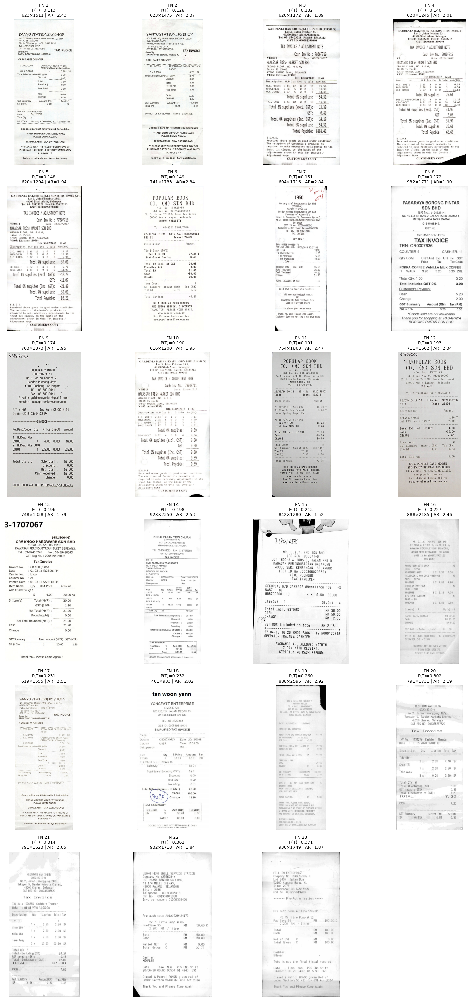


Saved: /kaggle/working/document_FN_23_detailed.png


In [67]:
import matplotlib.pyplot as plt
import math
from PIL import Image
import os

# Use the FN dataframe from the previous analysis
fn = fn_df.sort_values("P_tampered").reset_index(drop=True)

cols = 4
rows = math.ceil(len(fn) / cols)

fig = plt.figure(figsize=(16, rows * 5))

for i, row in fn.iterrows():

    img = Image.open(row["path"]).convert("RGB")

    ax = plt.subplot(rows, cols, i + 1)

    ax.imshow(img)

    ax.set_title(
        f"FN {i+1}\n"
        f"P(T)={row['P_tampered']:.3f}\n"
        f"{row['width']}×{row['height']} | "
        f"AR={row['aspect_ratio']:.2f}",
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()

output = "/kaggle/working/document_FN_23_detailed.png"

plt.savefig(
    output,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", output)

In [68]:
from PIL import Image
import os
import numpy as np
import pandas as pd

def analyze_folder(folder, label):

    rows = []

    extensions = (
        ".jpg", ".jpeg", ".png",
        ".bmp", ".webp",
        ".JPG", ".JPEG", ".PNG"
    )

    for root, _, files in os.walk(folder):

        for f in files:

            if not f.endswith(extensions):
                continue

            path = os.path.join(root, f)

            try:

                img = Image.open(path)

                w, h = img.size

                rows.append({
                    "label": label,
                    "width": w,
                    "height": h,
                    "aspect_ratio": h / w
                })

            except:
                pass

    return pd.DataFrame(rows)


train_auth = analyze_folder(
    os.path.join(TRAIN_DIR, "Authentic"),
    "Authentic"
)

train_tamp = analyze_folder(
    os.path.join(TRAIN_DIR, "Tampered_Forged"),
    "Tampered"
)

train_stats = pd.concat(
    [train_auth, train_tamp],
    ignore_index=True
)

print("=" * 70)
print("TRAINING IMAGE GEOMETRY")
print("=" * 70)

print(
    train_stats.groupby("label")[
        ["width", "height", "aspect_ratio"]
    ].mean().round(2)
)


# Tall receipt percentage
print("\n" + "=" * 70)
print("TALL DOCUMENTS (ASPECT RATIO > 1.5)")
print("=" * 70)

for label in ["Authentic", "Tampered"]:

    subset = train_stats[
        train_stats["label"] == label
    ]

    percentage = (
        (subset["aspect_ratio"] > 1.5).mean()
        * 100
    )

    print(
        f"{label}: "
        f"{percentage:.2f}%"
    )

TRAINING IMAGE GEOMETRY
            width   height  aspect_ratio
label                                   
Authentic  854.89  1146.46          1.20
Tampered   652.78   587.25          0.79

TALL DOCUMENTS (ASPECT RATIO > 1.5)
Authentic: 30.71%
Tampered: 8.48%


In [69]:
print("Tampered training images:", len(train_tamp))

tall_tampered = train_tamp[
    train_tamp["aspect_ratio"] > 1.5
]

print(
    "Tall Tampered (>1.5):",
    len(tall_tampered)
)

print(
    "Percentage:",
    round(
        len(tall_tampered) /
        len(train_tamp) * 100,
        2
    ),
    "%"
)

Tampered training images: 1038
Tall Tampered (>1.5): 88
Percentage: 8.48 %


In [70]:
# ============================================================
# FinGuard AI - Document Tampering
# Experiment 3:
# Targeted Oversampling + Realistic Augmentation
#
# IMPORTANT:
# - Same Custom CNN architecture
# - Same 224x224 preprocessing
# - Same validation set
# - Test set remains completely untouched
# ============================================================

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

DATA_DIR = (
    "/kaggle/input/datasets/pmaheswarraju/"
    "financial-tamper-dataset/FinGuard_Final_Dataset"
)

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "validation")
TEST_DIR = os.path.join(DATA_DIR, "test")

IMG_SIZE = 224
BATCH_SIZE = 32

CLASS_NAMES = [
    "Authentic",
    "Tampered_Forged"
]

MODEL_PATH = (
    "/kaggle/working/"
    "finguard_document_custom_cnn_targeted.keras"
)

print("=" * 70)
print("FinGuard AI - Targeted Tampered Training")
print("=" * 70)


# ------------------------------------------------------------
# 2. Get image paths
# ------------------------------------------------------------

def get_image_paths(folder):

    extensions = (
        ".jpg", ".jpeg", ".png", ".bmp", ".webp",
        ".JPG", ".JPEG", ".PNG"
    )

    items = []

    for class_idx, class_name in enumerate(CLASS_NAMES):

        class_dir = os.path.join(
            folder,
            class_name
        )

        for root, _, files in os.walk(class_dir):

            for filename in files:

                if filename.endswith(extensions):

                    items.append(
                        (
                            os.path.join(root, filename),
                            class_idx
                        )
                    )

    return sorted(items)


train_items = get_image_paths(TRAIN_DIR)
val_items = get_image_paths(VAL_DIR)
test_items = get_image_paths(TEST_DIR)

print("\nDataset:")
print("Train      :", len(train_items))
print("Validation :", len(val_items))
print("Test       :", len(test_items))


# ------------------------------------------------------------
# 3. Separate training classes
# ------------------------------------------------------------

authentic_train = [
    item for item in train_items
    if item[1] == 0
]

tampered_train = [
    item for item in train_items
    if item[1] == 1
]


# ------------------------------------------------------------
# 4. Identify tall Tampered training images
# ------------------------------------------------------------

def image_aspect_ratio(path):

    try:

        from PIL import Image

        img = Image.open(path)

        w, h = img.size

        return h / w

    except:

        return 0


tall_tampered = []

for item in tampered_train:

    path, label = item

    ar = image_aspect_ratio(path)

    if ar > 1.5:

        tall_tampered.append(item)


print("\nTampered training:")
print("Total Tampered :", len(tampered_train))
print("Tall Tampered  :", len(tall_tampered))
print(
    "Tall percentage:",
    round(
        100 * len(tall_tampered) /
        len(tampered_train),
        2
    ),
    "%"
)


# ------------------------------------------------------------
# 5. Create targeted oversampled training list
#
# We increase exposure of the existing tall Tampered images.
#
# We do NOT add any test images.
# We do NOT create stretched documents.
# ------------------------------------------------------------

# Repeat the tall Tampered subset 3 additional times.
# Original occurrence + 3 repeats = 4x exposure.

TARGETED_REPEAT = 3

targeted_tampered = (
    tampered_train +
    tall_tampered * TARGETED_REPEAT
)

targeted_train_items = (
    authentic_train +
    targeted_tampered
)

print("\nTargeted training distribution:")
print(
    "Authentic:",
    len(authentic_train)
)

print(
    "Tampered original:",
    len(tampered_train)
)

print(
    "Additional tall Tampered copies:",
    len(tall_tampered) * TARGETED_REPEAT
)

print(
    "Effective Tampered exposure:",
    len(targeted_tampered)
)

print(
    "Total training samples:",
    len(targeted_train_items)
)


# ------------------------------------------------------------
# 6. Original preprocessing
#
# IMPORTANT:
# We deliberately return to the original preprocessing because
# aspect-ratio preserving preprocessing did NOT improve results.
# ------------------------------------------------------------

def preprocess_document(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape(
        [None, None, 3]
    )

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    label = tf.cast(
        label,
        tf.float32
    )

    return image, label


# ------------------------------------------------------------
# 7. Training augmentation
# ------------------------------------------------------------

training_augmentation = tf.keras.Sequential([

    layers.RandomRotation(
        0.03
    ),

    layers.RandomZoom(
        0.10
    ),

    layers.RandomTranslation(
        0.05,
        0.05
    ),

    layers.RandomContrast(
        0.10
    )

], name="document_augmentation")


# ------------------------------------------------------------
# 8. Create datasets
# ------------------------------------------------------------

def make_dataset(
    items,
    shuffle=False
):

    paths = [
        item[0]
        for item in items
    ]

    labels = [
        item[1]
        for item in items
    ]

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:

        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        preprocess_document,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE
    )

    ds = ds.prefetch(
        tf.data.AUTOTUNE
    )

    return ds


train_ds_targeted = make_dataset(
    targeted_train_items,
    shuffle=True
)

val_ds_targeted = make_dataset(
    val_items,
    shuffle=False
)

test_ds_targeted = make_dataset(
    test_items,
    shuffle=False
)

print("\nDatasets created.")


# ------------------------------------------------------------
# 9. SAME Custom CNN
# ------------------------------------------------------------

def build_custom_cnn(
    input_shape=(224, 224, 3)
):

    inputs = layers.Input(
        shape=input_shape
    )

    x = training_augmentation(
        inputs
    )

    # Block 1
    x = layers.Conv2D(
        32,
        (3, 3),
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # Block 2
    x = layers.Conv2D(
        64,
        (3, 3),
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # Block 3
    x = layers.Conv2D(
        128,
        (3, 3),
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)

    x = layers.MaxPooling2D(
        (2, 2)
    )(x)


    # Block 4
    x = layers.Conv2D(
        256,
        (3, 3),
        padding="same"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)


    # Classification head
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(
        0.40
    )(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inputs,
        outputs,
        name="FinGuard_Custom_CNN_Targeted"
    )


model_targeted = build_custom_cnn()

print(
    "\nModel parameters:",
    model_targeted.count_params()
)


# ------------------------------------------------------------
# 10. Compile
# ------------------------------------------------------------

model_targeted.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=3e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)


# ------------------------------------------------------------
# 11. Callbacks
# ------------------------------------------------------------

callbacks_targeted = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_auc",

        mode="max",

        patience=5,

        restore_best_weights=True,

        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_auc",

        mode="max",

        factor=0.5,

        patience=2,

        min_lr=1e-6,

        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(

        MODEL_PATH,

        monitor="val_auc",

        mode="max",

        save_best_only=True,

        verbose=1
    )
]


# ------------------------------------------------------------
# 12. Train
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STARTING TARGETED TRAINING")
print("=" * 70)

history_targeted = model_targeted.fit(

    train_ds_targeted,

    validation_data=val_ds_targeted,

    epochs=30,

    callbacks=callbacks_targeted,

    verbose=1
)


# ------------------------------------------------------------
# 13. Load best model
# ------------------------------------------------------------

print("\nLoading best checkpoint...")

model_targeted = tf.keras.models.load_model(
    MODEL_PATH
)

print(
    "Loaded:",
    MODEL_PATH
)

print(
    "Parameters:",
    model_targeted.count_params()
)


# ------------------------------------------------------------
# 14. Test evaluation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

test_loss, test_accuracy, test_auc = (
    model_targeted.evaluate(
        test_ds_targeted,
        verbose=1
    )
)

print("\nTest Loss     :", round(test_loss, 4))
print("Test Accuracy :", round(test_accuracy, 4))
print("Test AUC      :", round(test_auc, 4))


# ------------------------------------------------------------
# 15. Predictions
# ------------------------------------------------------------

y_true = []
y_prob = []

for images, labels in test_ds_targeted:

    probabilities = model_targeted.predict(
        images,
        verbose=0
    ).ravel()

    y_prob.extend(
        probabilities.tolist()
    )

    y_true.extend(
        labels.numpy().tolist()
    )


y_true = np.array(
    y_true,
    dtype=int
)

y_prob = np.array(
    y_prob,
    dtype=float
)

y_pred = (
    y_prob >= 0.5
).astype(int)


# ------------------------------------------------------------
# 16. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives  :", tn)
print("False Positives :", fp)
print("False Negatives :", fn)
print("True Positives  :", tp)


# ------------------------------------------------------------
# 17. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)


# ------------------------------------------------------------
# 18. Tampered metrics
# ------------------------------------------------------------

tampered_precision = (
    tp / (tp + fp)
    if (tp + fp) > 0
    else 0
)

tampered_recall = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

tampered_f1 = (
    2 *
    tampered_precision *
    tampered_recall /
    (tampered_precision + tampered_recall)
    if (
        tampered_precision +
        tampered_recall
    ) > 0
    else 0
)

final_auc = roc_auc_score(
    y_true,
    y_prob
)

print("\n" + "=" * 70)
print("TAMPERED CLASS")
print("=" * 70)

print(
    "Precision :",
    round(tampered_precision, 4)
)

print(
    "Recall    :",
    round(tampered_recall, 4)
)

print(
    "F1        :",
    round(tampered_f1, 4)
)

print(
    "ROC-AUC   :",
    round(final_auc, 4)
)

print(
    "FN        :",
    fn
)

print(
    "FP        :",
    fp
)


# ------------------------------------------------------------
# 19. Save
# ------------------------------------------------------------

model_targeted.save(
    MODEL_PATH
)

print("\n" + "=" * 70)
print("MODEL SAVED")
print("=" * 70)

print(MODEL_PATH)

print(
    "Exists:",
    os.path.exists(MODEL_PATH)
)

FinGuard AI - Targeted Tampered Training

Dataset:
Train      : 2539
Validation : 544
Test       : 545

Tampered training:
Total Tampered : 1038
Tall Tampered  : 88
Tall percentage: 8.48 %

Targeted training distribution:
Authentic: 1501
Tampered original: 1038
Additional tall Tampered copies: 264
Effective Tampered exposure: 1302
Total training samples: 2803

Datasets created.

Model parameters: 423361

STARTING TARGETED TRAINING
Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.7858 - auc: 0.8823 - loss: 0.4135
Epoch 1: val_auc improved from None to 0.84923, saving model to /kaggle/working/finguard_document_custom_cnn_targeted.keras

Epoch 1: finished saving model to /kaggle/working/finguard_document_custom_cnn_targeted.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 226ms/step - accuracy: 0.8141 - auc: 0.9201 - loss: 0.3488 - val_accuracy: 0.4210 - val_auc: 0.8492 - val_loss: 0.7829 - learning_rate: 3.0000e-04
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.84

In [71]:
# ============================================================
# Compare baseline vs targeted model on the SAME test images
# ============================================================

# We already have:
# test_items
# model = original baseline
# model_targeted = targeted model

from PIL import Image
import numpy as np
import os

comparison = []

for path, label in test_items:

    if label != 1:
        continue

    img = Image.open(path).convert("RGB")
    img = img.resize((224, 224))

    arr = np.array(
        img,
        dtype=np.float32
    ) / 255.0

    tensor = np.expand_dims(
        arr,
        axis=0
    )

    p_base = float(
        model.predict(
            tensor,
            verbose=0
        ).ravel()[0]
    )

    p_target = float(
        model_targeted.predict(
            tensor,
            verbose=0
        ).ravel()[0]
    )

    comparison.append({
        "filename": os.path.basename(path),
        "baseline": p_base,
        "targeted": p_target,
        "change": p_target - p_base
    })


comparison_df = pd.DataFrame(comparison)

# Original baseline FNs
baseline_fn = comparison_df[
    comparison_df["baseline"] < 0.5
]

# Targeted FNs
targeted_fn = comparison_df[
    comparison_df["targeted"] < 0.5
]

# Fixed by targeted model
fixed = comparison_df[
    (comparison_df["baseline"] < 0.5) &
    (comparison_df["targeted"] >= 0.5)
]

# New errors
new_errors = comparison_df[
    (comparison_df["baseline"] >= 0.5) &
    (comparison_df["targeted"] < 0.5)
]

print("=" * 70)
print("BASELINE → TARGETED COMPARISON")
print("=" * 70)

print("Baseline FN :", len(baseline_fn))
print("Targeted FN :", len(targeted_fn))
print("Fixed       :", len(fixed))
print("New errors  :", len(new_errors))

print("\n" + "=" * 70)
print("FIXED FALSE NEGATIVES")
print("=" * 70)

if len(fixed) > 0:
    print(
        fixed.sort_values(
            "change",
            ascending=False
        ).to_string(index=False)
    )
else:
    print("None")


print("\n" + "=" * 70)
print("REMAINING FALSE NEGATIVES")
print("=" * 70)

print(
    targeted_fn.sort_values(
        "targeted"
    ).to_string(index=False)
)

BASELINE → TARGETED COMPARISON
Baseline FN : 23
Targeted FN : 19
Fixed       : 6
New errors  : 2

FIXED FALSE NEGATIVES
                             filename  baseline  targeted   change
 receipt_forged_test_X51005757349.png  0.174186  0.500938 0.326752
receipt_forged_train_X51006619343.png  0.227009  0.535138 0.308129
receipt_forged_train_X51006619550.png  0.259864  0.531976 0.272111
 receipt_forged_test_X51007339107.png  0.231356  0.500655 0.269300
receipt_forged_train_X51008042780.png  0.302094  0.500001 0.197907
receipt_forged_train_X51008114321.png  0.371416  0.513521 0.142105

REMAINING FALSE NEGATIVES
                             filename  baseline  targeted    change
receipt_forged_train_X51006913024.png  0.891138  0.220854 -0.670284
receipt_forged_train_X51006555806.png  0.148139  0.229462  0.081323
  receipt_forged_val_X51005605335.png  0.148601  0.233932  0.085331
 receipt_forged_test_X51006557117.png  0.139747  0.236270  0.096523
 receipt_forged_test_X51006556726.png  0.132